In [1]:
# ============================================================
# LOAD AND PREPARE WATER QUALITY DATA
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("../data/water_dataX.csv", encoding="latin1")

# ------------------------------------------------------------
# AUTHORITATIVE PARAMETER LIST
# ------------------------------------------------------------
# These 6 parameters are the only ones that enter the WQI and the
# only ones used as model inputs. The list is defined once here and
# reused by every later cell (cleaning -> WQI -> training -> save),
# so the notebook can no longer disagree with itself.
#
# 'Temp' is excluded because it appears in no rating band of this
# index: it carries no information about the target and only adds a
# free parameter the model can overfit.
#
# 'FECAL COLIFORM (MPN/100ml)' is excluded because it is not part of
# this index definition. Requiring it to be non-null discarded
# otherwise complete records for a parameter that never enters WQI.

FEATURES = [
    "D.O. (mg/l)",
    "PH",
    "CONDUCTIVITY (µmhos/cm)",
    "B.O.D. (mg/l)",
    "NITRATENAN N+ NITRITENANN (mg/l)",
    "TOTAL COLIFORM (MPN/100ml)Mean",
]

# Convert parameters to numeric
for col in FEATURES:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# ------------------------------------------------------------
# REMOVE CORRUPTED pH VALUES
# ------------------------------------------------------------

invalid_ph = (df["PH"] < 0) | (df["PH"] > 14)

print("Original rows:", len(df))
print("Invalid pH rows:", int(invalid_ph.sum()))

df = df[~invalid_ph].copy()

# Remove exact duplicate rows (all columns identical)
df = df.drop_duplicates()

# ------------------------------------------------------------
# KEEP ONLY COMPLETE RECORDS FOR THE 6 INDEX PARAMETERS
# ------------------------------------------------------------

model_df = df.dropna(subset=FEATURES).copy()

# ------------------------------------------------------------
# DUPLICATE PARAMETER-VECTOR AUDIT
# ------------------------------------------------------------
# Identical parameter vectors placed on both sides of the train/test
# split would make the reported accuracy optimistic, so any remaining
# exact duplicates are removed and the count is reported.

rows_before = len(model_df)
model_df = model_df.drop_duplicates(subset=FEATURES)

print("Rows after cleaning:", len(df))
print("Rows used for WQI/model:", len(model_df))
print("Duplicate parameter vectors removed:", rows_before - len(model_df))

print("\nMissing values:")
print(model_df[FEATURES].isna().sum())

print("\nModel dataset shape:", model_df.shape)

print("\nFeature ranges:")
print(model_df[FEATURES].describe().T[
    ["min", "50%", "mean", "max"]
])

# ============================================================
# model_df IS NOW READY FOR WQI CALCULATION
# ============================================================

Original rows: 1991
Invalid pH rows: 89
Rows after cleaning: 1901
Rows used for WQI/model: 1593
Duplicate parameter vectors removed: 1

Missing values:
D.O. (mg/l)                         0
PH                                  0
CONDUCTIVITY (µmhos/cm)             0
B.O.D. (mg/l)                       0
NITRATENAN N+ NITRITENANN (mg/l)    0
TOTAL COLIFORM (MPN/100ml)Mean      0
dtype: int64

Model dataset shape: (1593, 12)

Feature ranges:
                                   min     50%           mean           max
D.O. (mg/l)                        0.0    6.70       6.313311  1.000000e+01
PH                                 2.6    7.20       7.178596  9.010000e+00
CONDUCTIVITY (µmhos/cm)           11.0  183.00    1853.882191  4.715600e+04
B.O.D. (mg/l)                      0.1    1.80       5.263539  5.345000e+02
NITRATENAN N+ NITRITENANN (mg/l)   0.0    0.51       1.416986  5.810000e+01
TOTAL COLIFORM (MPN/100ml)Mean     0.0  552.00  618563.924357  5.110909e+08


## Water Quality Index used in this project

**Equation**

\[ \text{WQI} = \sum_{i=1}^{6} n_i \, w_i \]

where \(n_i \in \{0, 40, 60, 80, 100\}\) is the **discretely binned**
normalized rating of parameter *i* and \(w_i\) is its unit weight.

| Parameter | Band edges -> rating | \(w_i\) |
|---|---|---|
| pH | <6.5→0, 6.5–6.7→40, 6.7–6.8→60, 6.8–7.0→80, 7.0–8.5→100, 8.5–8.6→80, 8.6–8.8→60, 8.8–9.0→40, >9.0→0 | 0.165 |
| Dissolved Oxygen (mg/l) | <3→0, 3–4.1→40, 4.1–5.1→60, 5.1–6→80, ≥6→100 | 0.281 |
| BOD (mg/l) | 0–3→100, 3–6→80, 6–80→60, 80–125→40, >125→0 | 0.234 |
| Conductivity (µmhos/cm) | 0–75→100, 75–150→80, 150–225→60, 225–300→40, >300→0 | 0.009 |
| Nitrate + Nitrite (mg/l) | 0–20→100, 20–50→80, 50–100→60, 100–200→40, >200→0 | 0.028 |
| Total Coliform (MPN/100ml) | 0–5→100, 5–50→80, 50–500→60, 500–1000→40, >1000→0 | 0.281 |

### Properties that must be stated honestly

* \(\sum_i w_i = 0.998\), therefore the **attainable range is \([0, 99.8]\), not \([0, 100]\)**.
  The index is an unnormalised weighted sum, not a weighted average.
* `Temp` and `FECAL COLIFORM` do **not** appear in the index.
* Because the ratings are quantised into five levels, many different
  parameter combinations collapse onto the same WQI value. The number of
  distinct WQI values over the dataset is printed in the next cell.

### Relationship to Paper 6 (Brown et al. 1972 weighted arithmetic WQI)

Paper 6 computes a Weighted Arithmetic WQI. It is related to, but **not
identical to**, the index above:

| | Paper 6 / Brown et al. (1972) | This project |
|---|---|---|
| Rating \(q_i\) | **continuous**, from measured value vs ideal and permissible limits | **discrete**, five fixed bands |
| Ideal value \(V_i\) | used (0 for all but DO = 14.6 mg/l and pH = 7.0) | **not used** |
| Weights \(w_i\) | \(K/R_i\), inversely proportional to permissible limits, \(K\) a proportionality constant | fixed constants chosen per parameter |
| Aggregation | \(\sum q_i w_i / \sum w_i\) (normalised average) | \(\sum n_i w_i\) (**not** normalised) |
| Parameters | 7, including faecal coliform | 6, excluding faecal coliform |

The numeric unit weights, permissible limits and WQI class thresholds of
Paper 6 are published only in its **Supplementary material** (Tables 1S and
2S), which was not available to this project. The weights and band edges
above are therefore **this project's own index definition**; they were not
taken from the paper, and this implementation does not claim to reproduce it.

In [2]:
# ============================================================
# FINAL WQI CALCULATION
# ============================================================
# WQI = sum_i ( n_i * w_i )      -- see the methodology markdown cell.
#
# The scalar band functions below are kept verbatim from the original
# implementation so that the target variable stays bit-identical.
# The weights are consolidated into a single declarative table, and the
# result is cross-checked against the original term-by-term sum.

wqi_df = model_df.copy()


# ------------------------------------------------------------
# NORMALIZED WATER QUALITY RATINGS
# ------------------------------------------------------------

# pH
def calc_npH(x):
    if 7 <= x <= 8.5:
        return 100
    elif (8.5 < x <= 8.6) or (6.8 <= x < 7):
        return 80
    elif (8.6 < x <= 8.8) or (6.7 <= x < 6.8):
        return 60
    elif (8.8 < x <= 9) or (6.5 <= x < 6.7):
        return 40
    else:
        return 0


# Dissolved Oxygen
def calc_ndo(x):
    if x >= 6:
        return 100
    elif 5.1 <= x < 6:
        return 80
    elif 4.1 <= x < 5.1:
        return 60
    elif 3 <= x < 4.1:
        return 40
    else:
        return 0


# BOD
def calc_nbdo(x):
    if 0 <= x <= 3:
        return 100
    elif 3 < x <= 6:
        return 80
    elif 6 < x <= 80:
        return 60
    elif 80 < x <= 125:
        return 40
    else:
        return 0


# Conductivity
def calc_nec(x):
    if 0 <= x <= 75:
        return 100
    elif 75 < x <= 150:
        return 80
    elif 150 < x <= 225:
        return 60
    elif 225 < x <= 300:
        return 40
    else:
        return 0


# Nitrate
def calc_nna(x):
    if 0 <= x <= 20:
        return 100
    elif 20 < x <= 50:
        return 80
    elif 50 < x <= 100:
        return 60
    elif 100 < x <= 200:
        return 40
    else:
        return 0


# Total Coliform
def calc_nco(x):
    if 0 <= x <= 5:
        return 100
    elif 5 < x <= 50:
        return 80
    elif 50 < x <= 500:
        return 60
    elif 500 < x <= 1000:
        return 40
    else:
        return 0


# ------------------------------------------------------------
# APPLY RATINGS
# ------------------------------------------------------------

wqi_df["npH"] = wqi_df["PH"].apply(calc_npH)

wqi_df["ndo"] = wqi_df["D.O. (mg/l)"].apply(calc_ndo)

wqi_df["nbdo"] = wqi_df["B.O.D. (mg/l)"].apply(calc_nbdo)

wqi_df["nec"] = wqi_df[
    "CONDUCTIVITY (µmhos/cm)"
].apply(calc_nec)

wqi_df["nna"] = wqi_df[
    "NITRATENAN N+ NITRITENANN (mg/l)"
].apply(calc_nna)

wqi_df["nco"] = wqi_df[
    "TOTAL COLIFORM (MPN/100ml)Mean"
].apply(calc_nco)


# ------------------------------------------------------------
# UNIT WEIGHTS
# ------------------------------------------------------------

WEIGHTS = {
    "npH": 0.165,    # pH
    "ndo": 0.281,    # Dissolved Oxygen
    "nbdo": 0.234,   # Biochemical Oxygen Demand
    "nec": 0.009,    # Electrical Conductivity
    "nna": 0.028,    # Nitrate + Nitrite
    "nco": 0.281,    # Total Coliform
}

WEIGHT_SUM = sum(WEIGHTS.values())

print("Sum of unit weights:", WEIGHT_SUM)
print("Theoretical WQI range: [0, %.1f]" % (100 * WEIGHT_SUM))

assert abs(WEIGHT_SUM - 0.998) < 1e-12, WEIGHT_SUM

for _c in WEIGHTS:
    assert set(wqi_df[_c].unique()) <= {0, 40, 60, 80, 100}, _c


# ------------------------------------------------------------
# FINAL WQI
# ------------------------------------------------------------

wph = wqi_df["npH"] * WEIGHTS["npH"]
wdo = wqi_df["ndo"] * WEIGHTS["ndo"]
wbdo = wqi_df["nbdo"] * WEIGHTS["nbdo"]
wec = wqi_df["nec"] * WEIGHTS["nec"]
wna = wqi_df["nna"] * WEIGHTS["nna"]
wco = wqi_df["nco"] * WEIGHTS["nco"]

wqi_df["WQI"] = wph + wdo + wbdo + wec + wna + wco

# Guard: the weighted sum must equal the consolidated table exactly.
assert np.allclose(
    wqi_df["WQI"],
    sum(wqi_df[_c] * _w for _c, _w in WEIGHTS.items())
)

assert wqi_df["WQI"].max() <= 100 * WEIGHT_SUM + 1e-9


# ============================================================
# OUTPUT
# ============================================================

print("=" * 60)
print("FINAL WQI STATISTICS")
print("=" * 60)
print(wqi_df["WQI"].describe())

print("\n" + "=" * 60)
print("WQI RANGE")
print("=" * 60)
print("Minimum:", wqi_df["WQI"].min())
print("Maximum:", wqi_df["WQI"].max())
print("Median :", wqi_df["WQI"].median())

print("\n" + "=" * 60)
print("WQI QUANTISATION")
print("=" * 60)
print("Distinct WQI values:", wqi_df["WQI"].nunique(),
      "over", len(wqi_df), "rows")

print("\n" + "=" * 60)
print("WQI MISSING")
print("=" * 60)
print(wqi_df["WQI"].isna().sum())

print("\n" + "=" * 60)
print("FIRST 20 WQI VALUES")
print("=" * 60)

print(
    wqi_df[
        [
            "PH",
            "D.O. (mg/l)",
            "B.O.D. (mg/l)",
            "CONDUCTIVITY (µmhos/cm)",
            "NITRATENAN N+ NITRITENANN (mg/l)",
            "TOTAL COLIFORM (MPN/100ml)Mean",
            "npH",
            "ndo",
            "nbdo",
            "nec",
            "nna",
            "nco",
            "WQI"
        ]
    ].head(20).to_string(index=False)
)

print("\n" + "=" * 60)
print("WQI > 75")
print("=" * 60)
print((wqi_df["WQI"] > 75).sum())

print("\n" + "=" * 60)
print("WQI <= 75")
print("=" * 60)
print((wqi_df["WQI"] <= 75).sum())

print("\n" + "=" * 60)
print("FINAL SHAPE")
print("=" * 60)
print(wqi_df.shape)

Sum of unit weights: 0.9980000000000001
Theoretical WQI range: [0, 99.8]
FINAL WQI STATISTICS
count    1593.000000
mean       73.891777
std        14.114810
min        19.300000
25%        66.260000
50%        76.340000
75%        83.700000
max        99.620000
Name: WQI, dtype: float64

WQI RANGE
Minimum: 19.3
Maximum: 99.62
Median : 76.34

WQI QUANTISATION
Distinct WQI values: 238 over 1593 rows

WQI MISSING
0

FIRST 20 WQI VALUES
 PH  D.O. (mg/l)  B.O.D. (mg/l)  CONDUCTIVITY (µmhos/cm)  NITRATENAN N+ NITRITENANN (mg/l)  TOTAL COLIFORM (MPN/100ml)Mean  npH  ndo  nbdo  nec  nna  nco   WQI
7.2          5.7            2.0                    189.0                               0.2                          8391.0  100   80   100   60  100    0 65.72
6.9          6.3            1.7                    179.0                               0.1                          5330.0   80  100   100   60  100    0 68.04
6.9          5.8            3.8                     64.0                           

Training samples: 1274
Testing samples : 319

LEAKAGE AUDIT
Duplicate train/test parameter vectors: 0



MODEL COMPARISON
            Model      MAE     RMSE  R2 Score
Gradient Boosting 0.479315 0.785109  0.996797
    Random Forest 0.539877 1.315366  0.991009
    Decision Tree 0.717743 2.194243  0.974979
Linear Regression 8.038684 9.329377  0.547687



BEST HYPERPARAMETERS
{'learning_rate': 0.1, 'max_depth': 2, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 150}

Best Cross-Validation R2:
0.9932528402259158

FINAL TUNED GRADIENT BOOSTING MODEL
MAE  : 0.5115485656712078
RMSE : 0.8515974580984711
R²   : 0.9962312051422298

ACTUAL VS PREDICTED
 Actual WQI  Predicted WQI
      88.02      87.868696
      85.08      85.186272
      55.20      55.958003
      71.70      71.541410
      88.60      88.629818
      82.94      82.220945
      94.00      94.025309
      82.04      83.040919
      44.58      43.781908
      71.52      71.362710
      60.90      65.158916
      70.80      70.873969
      71.70      71.541410
      70.80      70.824947
      71.70      71.488935
      94.18      94.111192
      89.32      89.268065
      71.70      71.541410
      78.30      78.293263
      67.06      68.730076


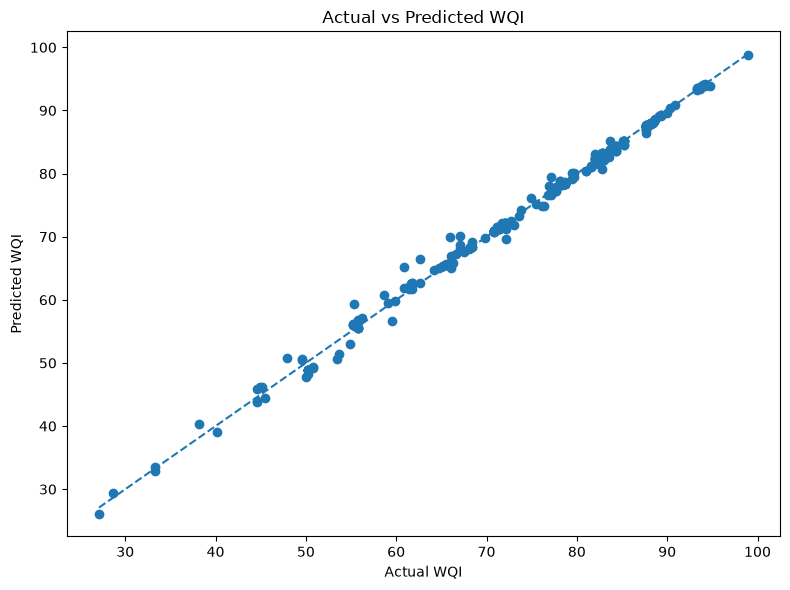


FEATURE IMPORTANCE
                         Feature   Importance
  TOTAL COLIFORM (MPN/100ml)Mean 5.113406e-01
                     D.O. (mg/l) 3.053475e-01
                              PH 1.120184e-01
                   B.O.D. (mg/l) 7.048698e-02
         CONDUCTIVITY (µmhos/cm) 8.057559e-04
NITRATENAN N+ NITRITENANN (mg/l) 7.207601e-07


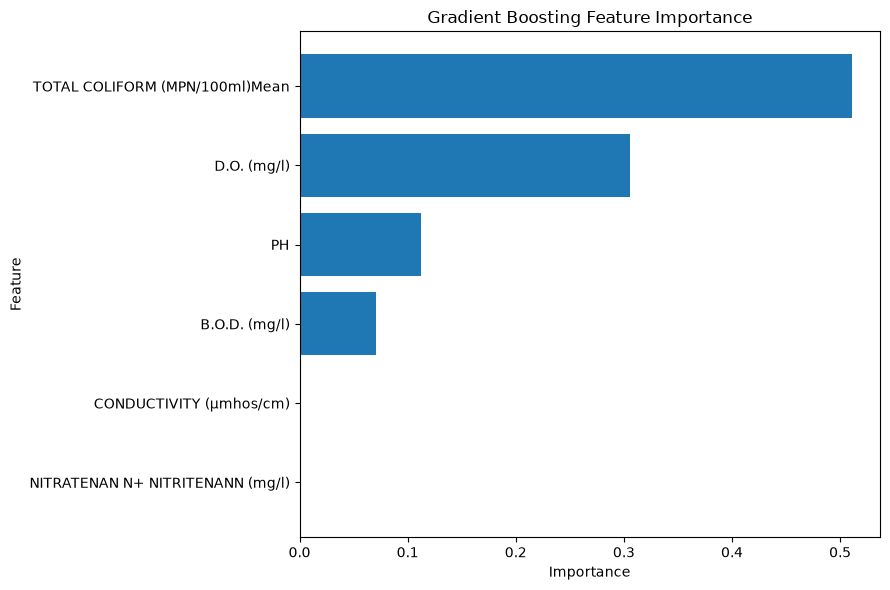


SHAP FEATURE IMPORTANCE


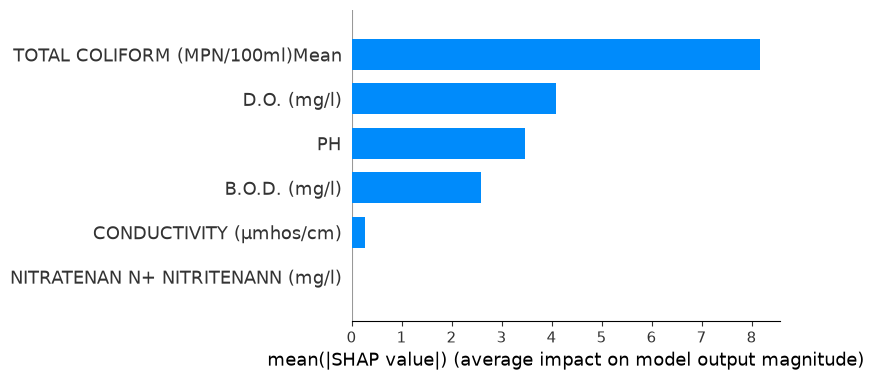


RUN MANIFEST
Samples            : 1593
Features           : 6
Train / Test       : 1274 / 319
Target max possible: 99.80000000000001
sklearn version    : 1.9.0
shap version       : 0.52.0


In [3]:
# ============================================================
# AI WATER QUALITY PREDICTION MODEL
# ============================================================

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import shap


# ============================================================
# FEATURES AND TARGET
# ============================================================
# FEATURES is the single 6-parameter list defined in the first cell,
# so data cleaning, WQI calculation and model training cannot diverge.

X = wqi_df[FEATURES]
y = wqi_df["WQI"]


# ============================================================
# TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

# ------------------------------------------------------------
# LEAKAGE AUDIT
# ------------------------------------------------------------
# Report any identical parameter vector that appears in both splits.
_keys = X.astype(str).agg("|".join, axis=1)
_leaked = int(_keys.loc[X_test.index].isin(_keys.loc[X_train.index]).sum())

print("\n" + "=" * 60)
print("LEAKAGE AUDIT")
print("=" * 60)
print("Duplicate train/test parameter vectors:", _leaked)


# ============================================================
# MODEL COMPARISON
# ============================================================

models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    )
}

results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2 Score": r2_score(y_test, predictions)
    })


results_df = pd.DataFrame(results)

print("\n" + "=" * 60)
print("MODEL COMPARISON")
print("=" * 60)

print(
    results_df
    .sort_values("R2 Score", ascending=False)
    .to_string(index=False)
)


# ============================================================
# HYPERPARAMETER TUNING
# ============================================================

gb = GradientBoostingRegressor(random_state=42)

param_grid = {
    "n_estimators": [50, 100, 150],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [2, 3, 4],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

grid_search = GridSearchCV(
    gb,
    param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("\n" + "=" * 60)
print("BEST HYPERPARAMETERS")
print("=" * 60)

print(grid_search.best_params_)

print("\nBest Cross-Validation R2:")
print(grid_search.best_score_)


# ============================================================
# FINAL TUNED MODEL
# ============================================================

best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n" + "=" * 60)
print("FINAL TUNED GRADIENT BOOSTING MODEL")
print("=" * 60)

print("MAE  :", mae)
print("RMSE :", rmse)
print("R²   :", r2)


# ============================================================
# ACTUAL VS PREDICTED
# ============================================================

comparison = pd.DataFrame({
    "Actual WQI": y_test.values,
    "Predicted WQI": y_pred
})

print("\n" + "=" * 60)
print("ACTUAL VS PREDICTED")
print("=" * 60)

print(comparison.head(20).to_string(index=False))


# ============================================================
# ACTUAL VS PREDICTED PLOT
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual WQI")
plt.ylabel("Predicted WQI")
plt.title("Actual vs Predicted WQI")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.tight_layout()
plt.show()


# ============================================================
# FEATURE IMPORTANCE
# ============================================================

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": best_model.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

print("\n" + "=" * 60)
print("FEATURE IMPORTANCE")
print("=" * 60)

print(importance.to_string(index=False))


# ============================================================
# FEATURE IMPORTANCE PLOT
# ============================================================

plt.figure(figsize=(9, 6))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Gradient Boosting Feature Importance")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()


# ============================================================
# SHAP ANALYSIS
# ============================================================

explainer = shap.TreeExplainer(best_model)

shap_values = explainer.shap_values(X_test)

print("\n" + "=" * 60)
print("SHAP FEATURE IMPORTANCE")
print("=" * 60)

shap.summary_plot(
    shap_values,
    X_test,
    plot_type="bar"
)


# ============================================================
# RUN MANIFEST
# ============================================================

print("\n" + "=" * 60)
print("RUN MANIFEST")
print("=" * 60)
print("Samples            :", len(wqi_df))
print("Features           :", len(FEATURES))
print("Train / Test       :", len(X_train), "/", len(X_test))
print("Target max possible:", 100 * WEIGHT_SUM)
print("sklearn version    :", sklearn.__version__)
print("shap version       :", shap.__version__)

In [4]:
import joblib

joblib.dump(best_model, "../model/wqi_model.pkl")
joblib.dump(FEATURES, "../model/features.pkl")

print("Model saved successfully!")
print("Model type      :", type(best_model).__name__)
print("n_features_in_  :", best_model.n_features_in_)
print("Features written:", FEATURES)

Model saved successfully!
Model type      : GradientBoostingRegressor
n_features_in_  : 6
Features written: ['D.O. (mg/l)', 'PH', 'CONDUCTIVITY (µmhos/cm)', 'B.O.D. (mg/l)', 'NITRATENAN N+ NITRITENANN (mg/l)', 'TOTAL COLIFORM (MPN/100ml)Mean']
